In [1]:
import os 
import json
import numpy as np 
import h5py
import matplotlib.pyplot as plt
import corner
import fitting_library as fl
from qsogen import fast_sed
from qsogen import model_colours
from scipy.stats import binned_statistic
import prepare_sample
from scipy.stats import norm
import results_library as rl

In [2]:
filenames = rl.get_filenames()
print(filenames)
filename = 'histogram_population_20260318_183100_937383'
data, config = rl.load_data(filename, burnin = 1000)
filename = 'normal_population_20260309_180142_449353'
data_norm, config_norm = rl.load_data(filename, burnin = 1000)


['normal_population_20260309_180142_449353', 'histogram_population_20260318_183100_937383']


In [3]:
hist_edges, hist_centers = rl.get_histograms_bins(config)
hist_weights = np.median(data, axis = 0)
dx = np.diff(hist_edges, axis=1)
hist_weights  = hist_weights / np.sum(hist_weights * dx, axis=1, keepdims=True)
median_norm = np.median(data_norm, axis =0)

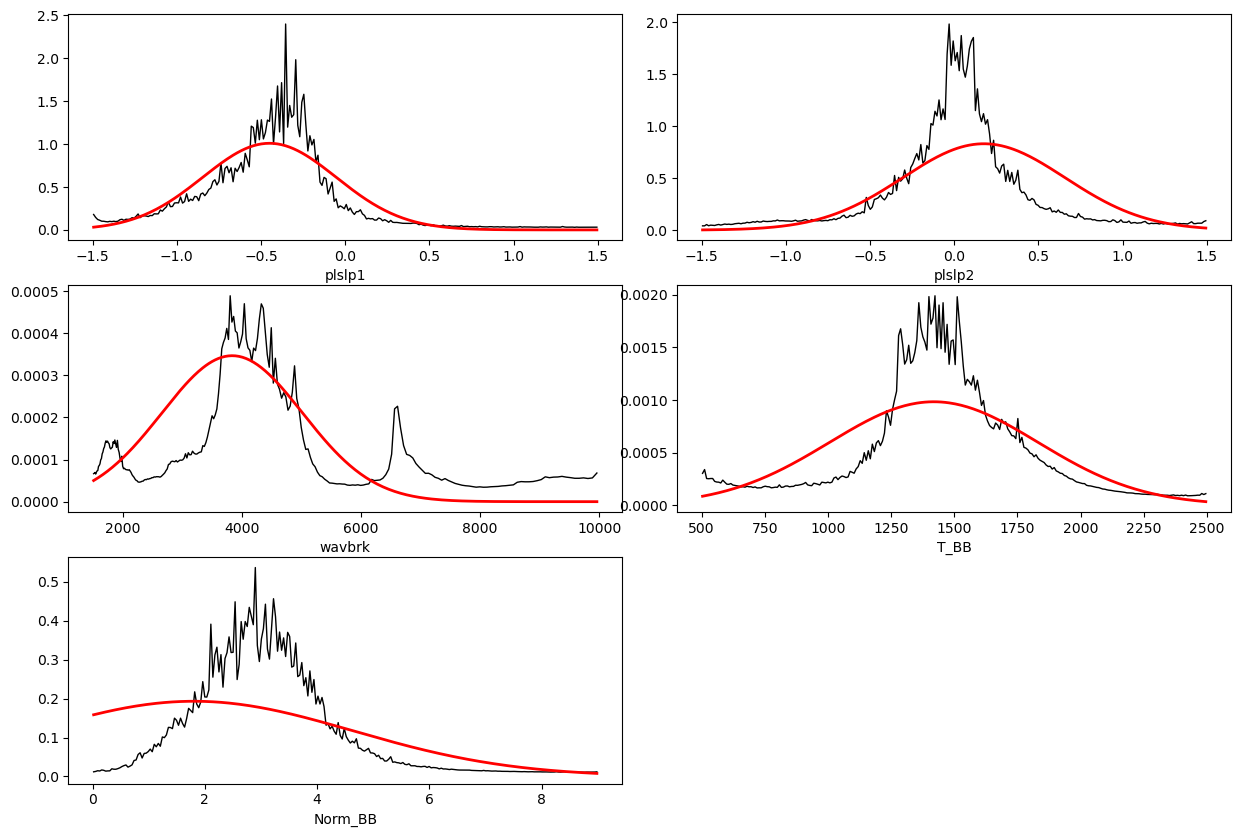

In [4]:
fig, ax = rl.get_parameters_figure()
rl.plot_parameters_hist(ax, hist_centers, hist_weights)
rl.plot_parameters_normal(ax, median_norm[...,0], median_norm[...,1], xvalues = hist_centers, lw =2)

In [6]:
redshift, y, yerr, m_i = rl.get_real_colors(config)

Transforming SDSS.u to AB, i.e. adding 0.0
Transforming SDSS.g to AB, i.e. adding 0.0
Transforming SDSS.r to AB, i.e. adding 0.0
Transforming SDSS.i to AB, i.e. adding 0.0
Transforming SDSS.z to AB, i.e. adding 0.0
Transforming UKIDSS.Y to AB, i.e. adding 0.6147726766033728
Transforming UKIDSS.J to AB, i.e. adding 0.9152606087248839
Transforming UKIDSS.H to AB, i.e. adding 1.3520471317250795
Transforming UKIDSS.K to AB, i.e. adding 1.8713980229183953
Transforming WISE.W1 to AB, i.e. adding 2.6787715820675913
Transforming WISE.W2 to AB, i.e. adding 3.3151986991103968
Keeping 35280 QSOs with 45.5 <= L < inf  at lambda = 5100 A
Keeping 35280 QSOs with 0 <= UKIDSS.Y <= 28
Keeping 24963 QSOs with err_SDSS.u < 0.1
Keeping 24911 QSOs with err_SDSS.g < 0.1
Keeping 24873 QSOs with err_SDSS.r < 0.1
Keeping 24828 QSOs with err_SDSS.i < 0.1
Keeping 23980 QSOs with err_SDSS.z < 0.1
Keeping 23593 QSOs with err_UKIDSS.Y < 0.1
Keeping 22666 QSOs with err_UKIDSS.J < 0.1
Keeping 19531 QSOs with err_UKID

In [7]:
theta = rl.get_sim_theta(len(redshift), hist_weights = hist_weights, 
                hist_edges = hist_edges,)
sim_colors = rl.get_sim_colors(redshift, theta, m_i)

(-0.1, 2.5)

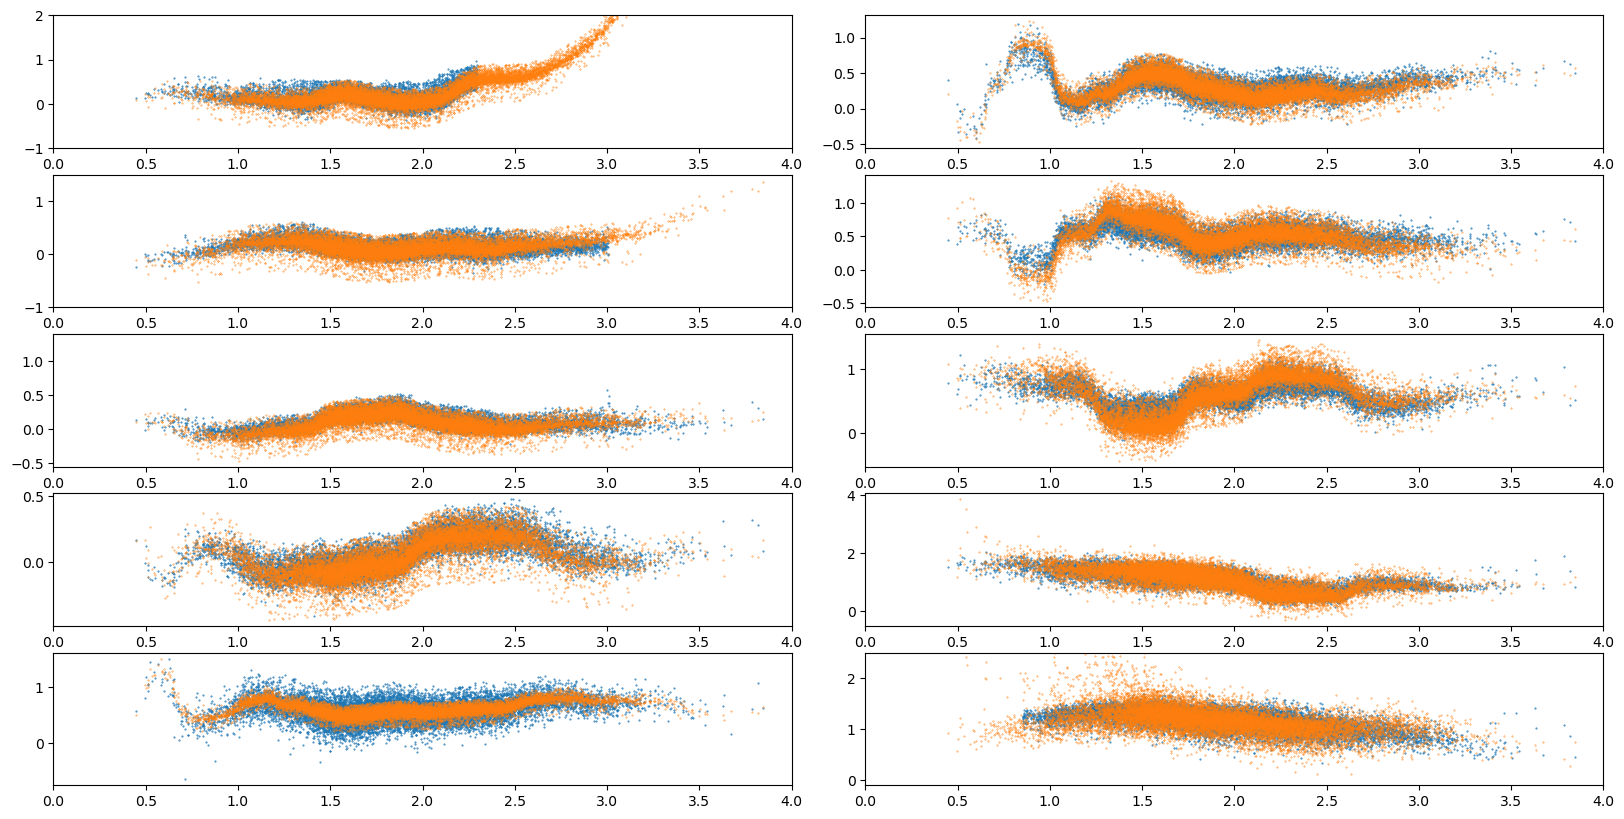

In [33]:
fig, axs = plt.subplots(nrows =5, ncols =2, figsize = (20,10), gridspec_kw={"wspace": 0.1})
for i in range(10):
    row = i % 5
    col = i // 5
    axs[row, col].scatter(redshift, y[:,i], s = 0.2)
    axs[row, col].scatter(redshift, sim_colors[:,i], s = 0.1)
    axs[row, col].set_xlim(0, 4)
axs[0,0].set_ylim(-1,2)
axs[1,0].set_ylim(-1,1.5)
axs[4,1].set_ylim(-0.1,2.5)

In [18]:
5//5

1

In [26]:
maindir = os.path.expanduser("~/DATA/MC_CHAINS")
print(os.listdir(maindir))
filename = 'histogram_population_20260318_183100_937383.h5'
filename_normal = 'normal_population_20260309_180142_449353.h5'
filename_json = filename.replace(".h5", ".json")
fname = os.path.join(maindir, filename)
fname_normal = os.path.join(maindir, filename_normal)


with open(os.path.join(maindir, filename_json)) as f:
    config = json.load(f)

['normal_population_20260309_180142_449353.json', 'normal_population_20260309_180142_449353.h5', 'histogram_population_20260318_183100_937383.json', 'histogram_population_20260318_183100_937383.h5']


In [27]:
burnin = 1000
with h5py.File(fname, "r") as f:
    data =f["trace"][:]
data = data[burnin:,...]
with h5py.File(fname_normal, "r") as f:
    normal_data =f["trace"][:]
normal_data = normal_data[burnin:,...]

In [28]:
options = config.get("gibbs_sampler", {})
Nbins = options["Nbins_hist"]
plslp1 = np.linspace(options["plslp1_hist"][0], options["plslp1_hist"][1], Nbins+1)
plslp2 = np.linspace(options["plslp2_hist"][0], options["plslp2_hist"][1], Nbins+1)
tbb = np.linspace(options["tbb_hist"][0], options["tbb_hist"][1], Nbins+1)
bbnorm = np.linspace(options["bbnorm_hist"][0], options["bbnorm_hist"][1], Nbins+1)
if options["wavbrk_hist_log"]:
    wavbreak = np.logspace(np.log10(options["wavbrk_hist"][0]), np.log10(options["wavbrk_hist"][1]),  Nbins+1)
else:
    wavbreak = np.linspace(options["wavbrk_hist"][0],options["wavbrk_hist"][1],  Nbins+1) 
hist_edges = np.column_stack((plslp1, plslp2, wavbreak, tbb, bbnorm)).T
hist_centers = 0.5*(hist_edges[:, :-1]+hist_edges[:, 1:])

In [29]:
median_weights = np.median(data, axis = 0)
median_mean = np.median(normal_data[...,0 ], axis =0)
median_sigma = np.sqrt(np.median(normal_data[...,1], axis =0))
median_weights = median_weights/np.sum(median_weights, axis =1)[:,None]

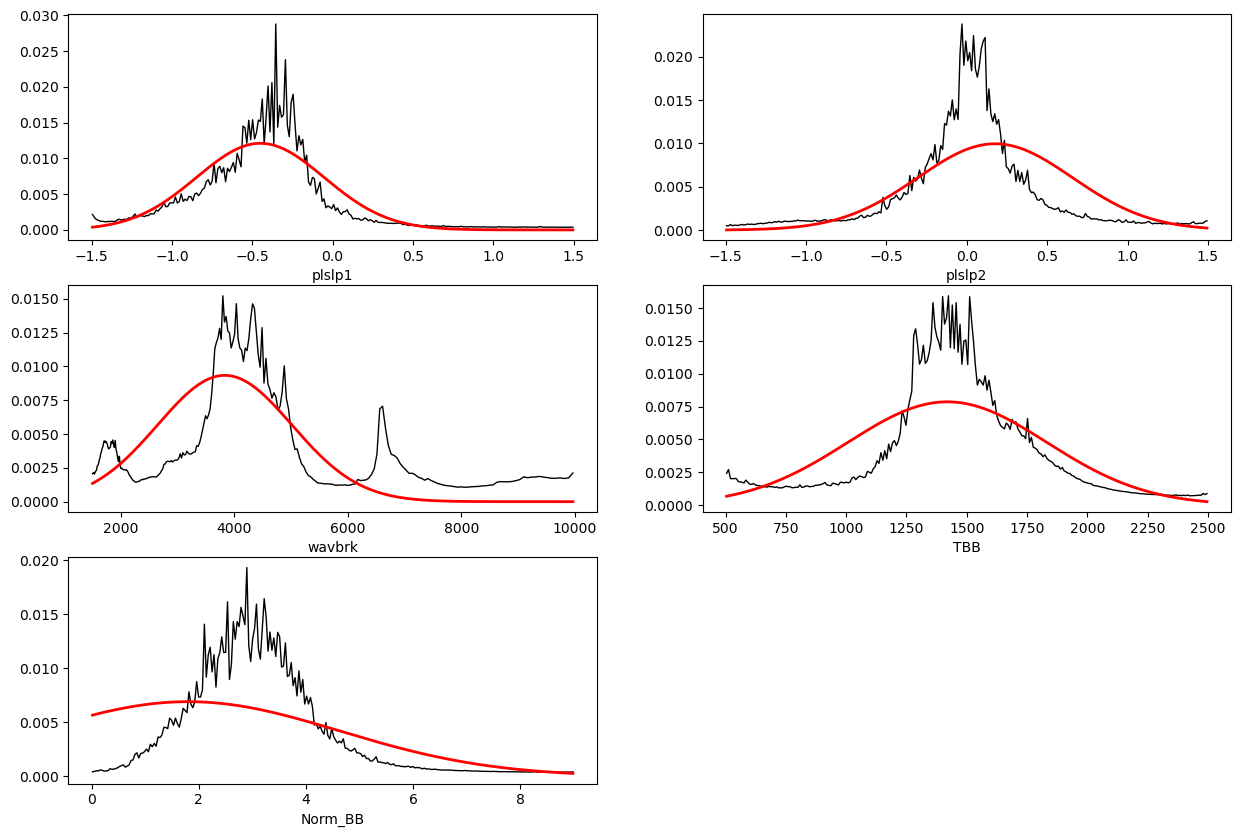

In [30]:
names = ["plslp1", "plslp2", "wavbrk", "TBB", "Norm_BB"]
fig, axs = plt.subplots(nrows =3, ncols =2, figsize = (15,10))
for idx in range(5):
    row = idx // 2
    col = idx % 2
    gauss = Normal(mu = median_mean[idx], sigma = median_sigma[idx])
    curve =  gauss.pdf(hist_centers[idx, :])
    curve = curve/np.sum(curve)
    axs[row,col].plot(hist_centers[idx, :], median_weights[idx,:], lw = 1, c= "k")
    axs[row,col].plot(hist_centers[idx, :],curve, lw = 2, c= "r")
    axs[row,col].set_xlabel(names[idx])

axs[2,1].set_axis_off()

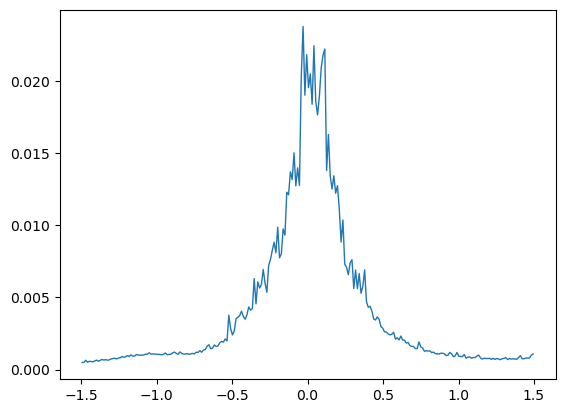

In [31]:
idx = 1
fig, ax = plt.subplots()
ax.plot(hist_centers[idx, :], median_weights[idx,:], lw = 1)

In [32]:
options = config.get("sample", {})
sample_table = prepare_sample.prepare_sample(filename = options["SDSS_QSOs_filename"],
                                       luminosity_cuts_low = options["luminosity_cuts_low"],
                                       wavelength_cuts = options["wavelength_cuts"],
                                       magnitudes_min = options["magnitudes_min"],
                                       magnitudes_max = options["magnitudes_max"],
                                       filtro_cuts = options["filtro_cuts"],
                                       filtri_uncertainties = options["filtri_uncertainties"],
                                       uncertainties_thresholds = options["uncertainties_thresholds"], 
                                       redshift_cut = options["redshift_cut"],
                                       directory = os.path.expanduser(options["SDSS_QSOs_path"]),
                                       return_only_magnitudes=False,
                                       )

colors = prepare_sample.color_container_class(sample_table)
colors.process_pipeline(**config["binning"])
redshift, y, yerr, m_i = colors.get_arrays(clipped = True)
Nagn = y.shape[0]

Transforming SDSS.u to AB, i.e. adding 0.0
Transforming SDSS.g to AB, i.e. adding 0.0
Transforming SDSS.r to AB, i.e. adding 0.0
Transforming SDSS.i to AB, i.e. adding 0.0
Transforming SDSS.z to AB, i.e. adding 0.0
Transforming UKIDSS.Y to AB, i.e. adding 0.6147726766033728
Transforming UKIDSS.J to AB, i.e. adding 0.9152606087248839
Transforming UKIDSS.H to AB, i.e. adding 1.3520471317250795
Transforming UKIDSS.K to AB, i.e. adding 1.8713980229183953
Transforming WISE.W1 to AB, i.e. adding 2.6787715820675913
Transforming WISE.W2 to AB, i.e. adding 3.3151986991103968
Keeping 35280 QSOs with 45.5 <= L < inf  at lambda = 5100 A
Keeping 35280 QSOs with 0 <= UKIDSS.Y <= 28
Keeping 24963 QSOs with err_SDSS.u < 0.1
Keeping 24911 QSOs with err_SDSS.g < 0.1
Keeping 24873 QSOs with err_SDSS.r < 0.1
Keeping 24828 QSOs with err_SDSS.i < 0.1
Keeping 23980 QSOs with err_SDSS.z < 0.1
Keeping 23593 QSOs with err_UKIDSS.Y < 0.1
Keeping 22666 QSOs with err_UKIDSS.J < 0.1
Keeping 19531 QSOs with err_UKID

In [30]:
median_weights.shape

(5, 250)

In [33]:
median_weights = median_weights/np.sum(median_weights, axis =1)[:,None]

theta = fl.sample_from_hist(Nagn, hist_edges,  median_weights)

In [33]:
#means = data[..., 0]
#sigmas = np.sqrt(data[..., 1])
#idx = np.random.choice(len(means), size=Nagn, replace=True)
#sampled_means = means[idx]
#sampled_sigmas = sigmas[idx]
#fake = np.array([
#    np.random.multivariate_normal(mean=m, cov=np.diag(s**2))
#    for m, s in zip(sampled_means, sampled_sigmas)])
#corner.corner(fake);

In [34]:
interps = fast_sed.make_interps()
emlines_grid = fast_sed.build_template_grid(interps)
filter_properties = model_colours.get_filters_properties()

In [35]:
theta = np.column_stack([redshift, theta, m_i])
sim_colors = fast_sed.get_colours_fast(theta, emlines_grid, filter_properties)

In [36]:
def mean(x):
    return np.nanmean(x)
def std(x):
    return np.nanstd(x)

In [37]:
redshift_bins = np.arange(0,3, 0.1)
Nbins = len(redshift_bins)-1
Ncolors =  y.shape[1]
mean_real_colors = np.zeros((Nbins, Ncolors, 2))
mean_sim_colors = np.zeros((Nbins, Ncolors, 2))
for i in range(Ncolors):
    mean_real_colors[:, i, 0], edges, _ = binned_statistic(redshift, y[:,i], bins = redshift_bins, statistic = "mean")
    mean_real_colors[:, i, 1], _, _ = binned_statistic(redshift, y[:,i], bins = redshift_bins, statistic = "std")
    mean_sim_colors[:, i, 0], _,_ = binned_statistic(redshift, sim_colors[:,i], bins = redshift_bins, statistic = mean)
    mean_sim_colors[:, i, 1],_, _ = binned_statistic(redshift, sim_colors[:,i], bins = redshift_bins, statistic = std)
mean_z = 0.5*(edges[:-1]+edges[1:])

In [38]:
Ncolors

10

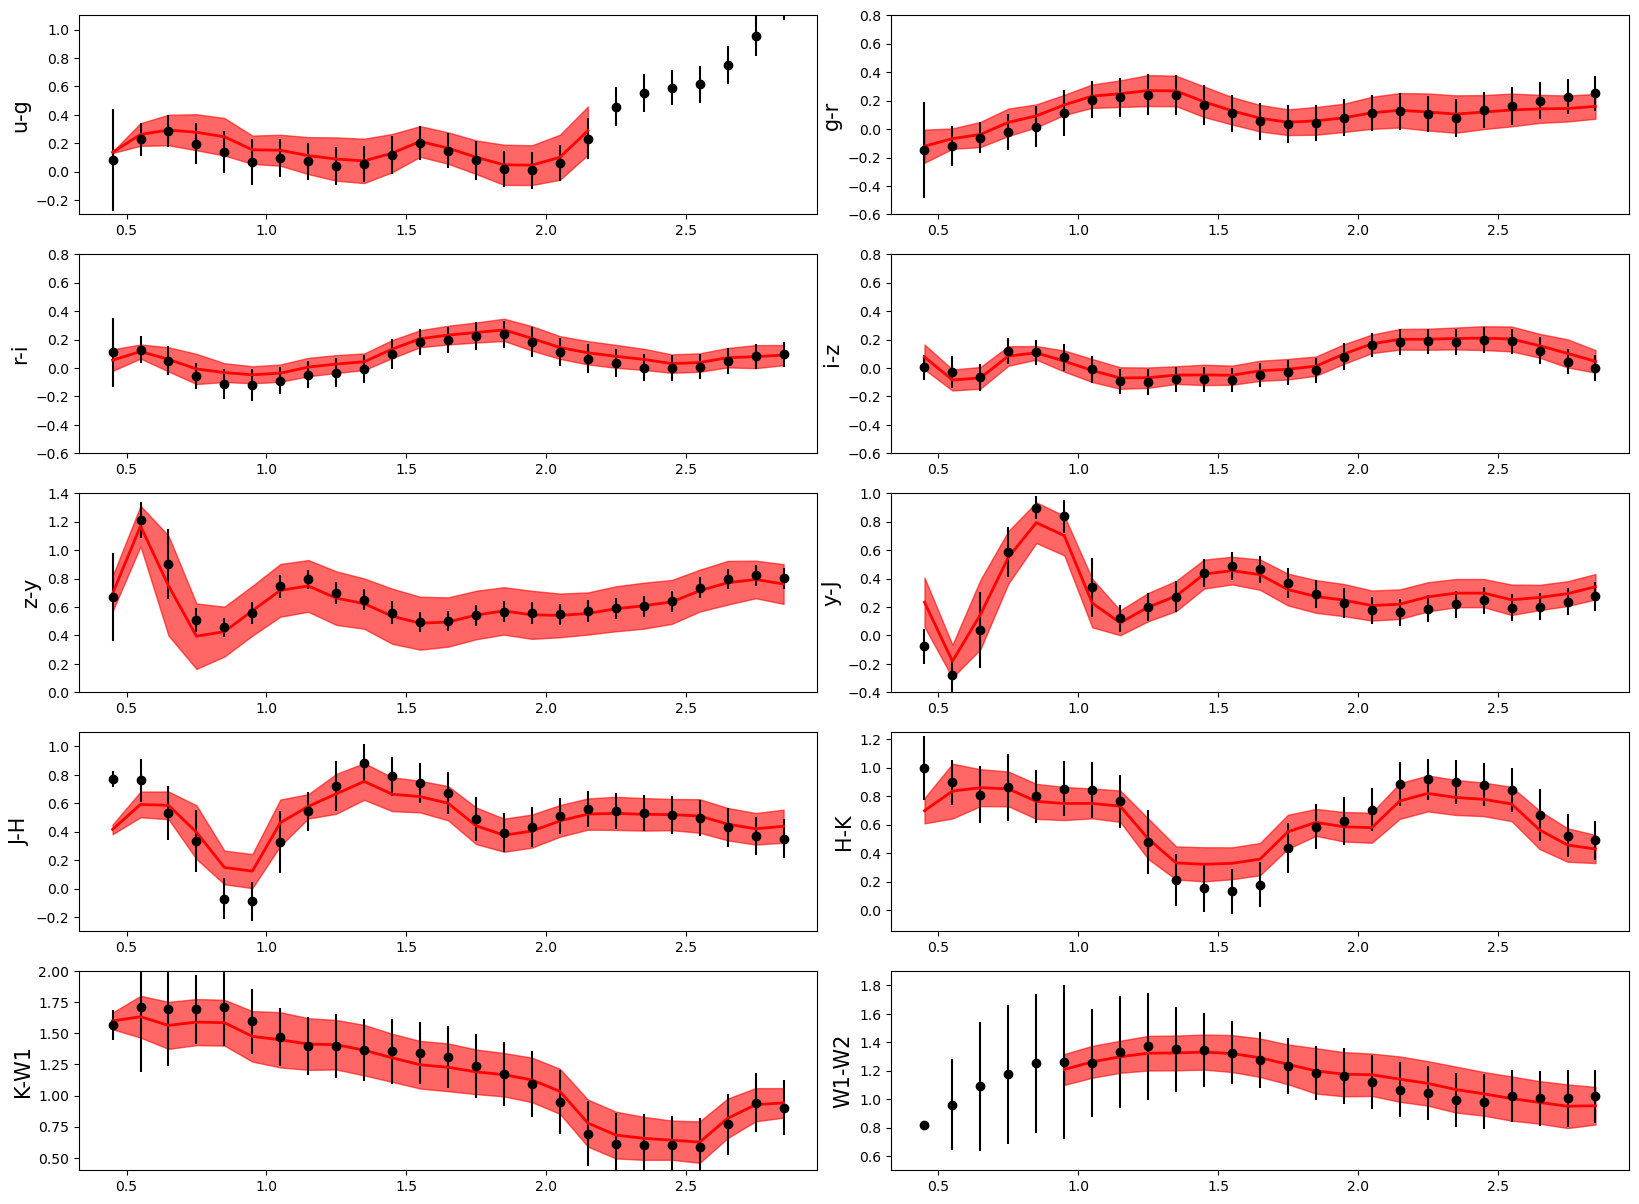

In [48]:
xlims = ((-0.3, 1.1), (-0.6, 0.8),  (-0.6, 0.8), (-0.6, 0.8), 
         (0.0,1.4),   (-0.4, 1.),(-0.3, 1.1), (-0.15,1.25),
         (0.4, 2), (0.5, 1.9))
ylabels = ("u-g", "g-r", "r-i", "i-z", "z-y", "y-J", "J-H", "H-K", "K-W1", "W1-W2")
fig, axs = plt.subplots(nrows = Ncolors//2, ncols =2, figsize = (20, 15), gridspec_kw = {'wspace':0.1})
for i in range(Ncolors):
    row = i//2
    col = i%2
    axs[row, col].errorbar(mean_z,  mean_sim_colors[:, i, 0],  mean_sim_colors[:, i, 1], c="k", ls = "none", marker ="o")
    axs[row, col].fill_between(mean_z,  mean_real_colors[:, i, 0]-mean_real_colors[:, i, 1],
                               mean_real_colors[:, i, 0]+mean_real_colors[:, i, 1], color ="r", alpha = 0.6)
    axs[row, col].plot(mean_z,  mean_real_colors[:, i, 0], color ="r", ls = "-", lw =2) 
    axs[row, col].set_ylim(*xlims[i])   
    axs[row, col].set_ylabel(ylabels[i], fontsize =15)                         

In [ ]:
def get_colors_figure(set_ylims = True, 
                    figsize = (20, 15), gridspec_kw = {'wspace':0.1}):

    ylims = ((-0.3, 1.1), (-0.6, 0.8),  (-0.6, 0.8), (-0.6, 0.8), (0.0,1.4),   (-0.4, 1.),
             (-0.3, 1.1), (-0.15,1.25),(0.4, 2), (0.5, 1.9))
    ylabels = ("u-g", "g-r", "r-i", "i-z", "z-y", "y-J", "J-H", "H-K", "K-W1", "W1-W2")        
    fig, axs = plt.subplots(nrows = 5, ncols =2, figsize = figsize, gridspec_kw = gridspec_kw)
    for i in range(10):
        row = i//2
        col = i%2
        axs[row, col].set_ylabel(ylabels[i], fontsize =15)
        if set_ylims:
            axs[row, col].set_ylim(*ylims[i])      
    return fig, axs 

def plot_colors_errorbars(axs, x, y, dy, c = "k", ls = "none", marker = "o", **kwargs):
    params = dict(c=c, ls=ls, marker=marker)
    params.update(kwargs) 
    for i in range(Ncolors):
        row = i//2
        col = i%2
        axs[row, col].errorbar(x,  y[:,i], dy[:,i] , **params)


def plot_colors_filled(axs, x, y, dy, plot_line = True, 
                    color = "red", alpha = 0.5, edgecolor = "none", **kwargs):
    params = dict(color = color, alpha = alpha, edgecolor=edgecolor)
    params.update(kwargs)
    for i in range(Ncolors):
        row = i//2
        col = i%2
        axs[row, col].fill_between(x,  y[:,i]-dy[:,i], y[:,i]+dy[:,i] , **params)
        if plot_line:
            axs[row, col].plot(x,  y[:,i] , color = color)


    



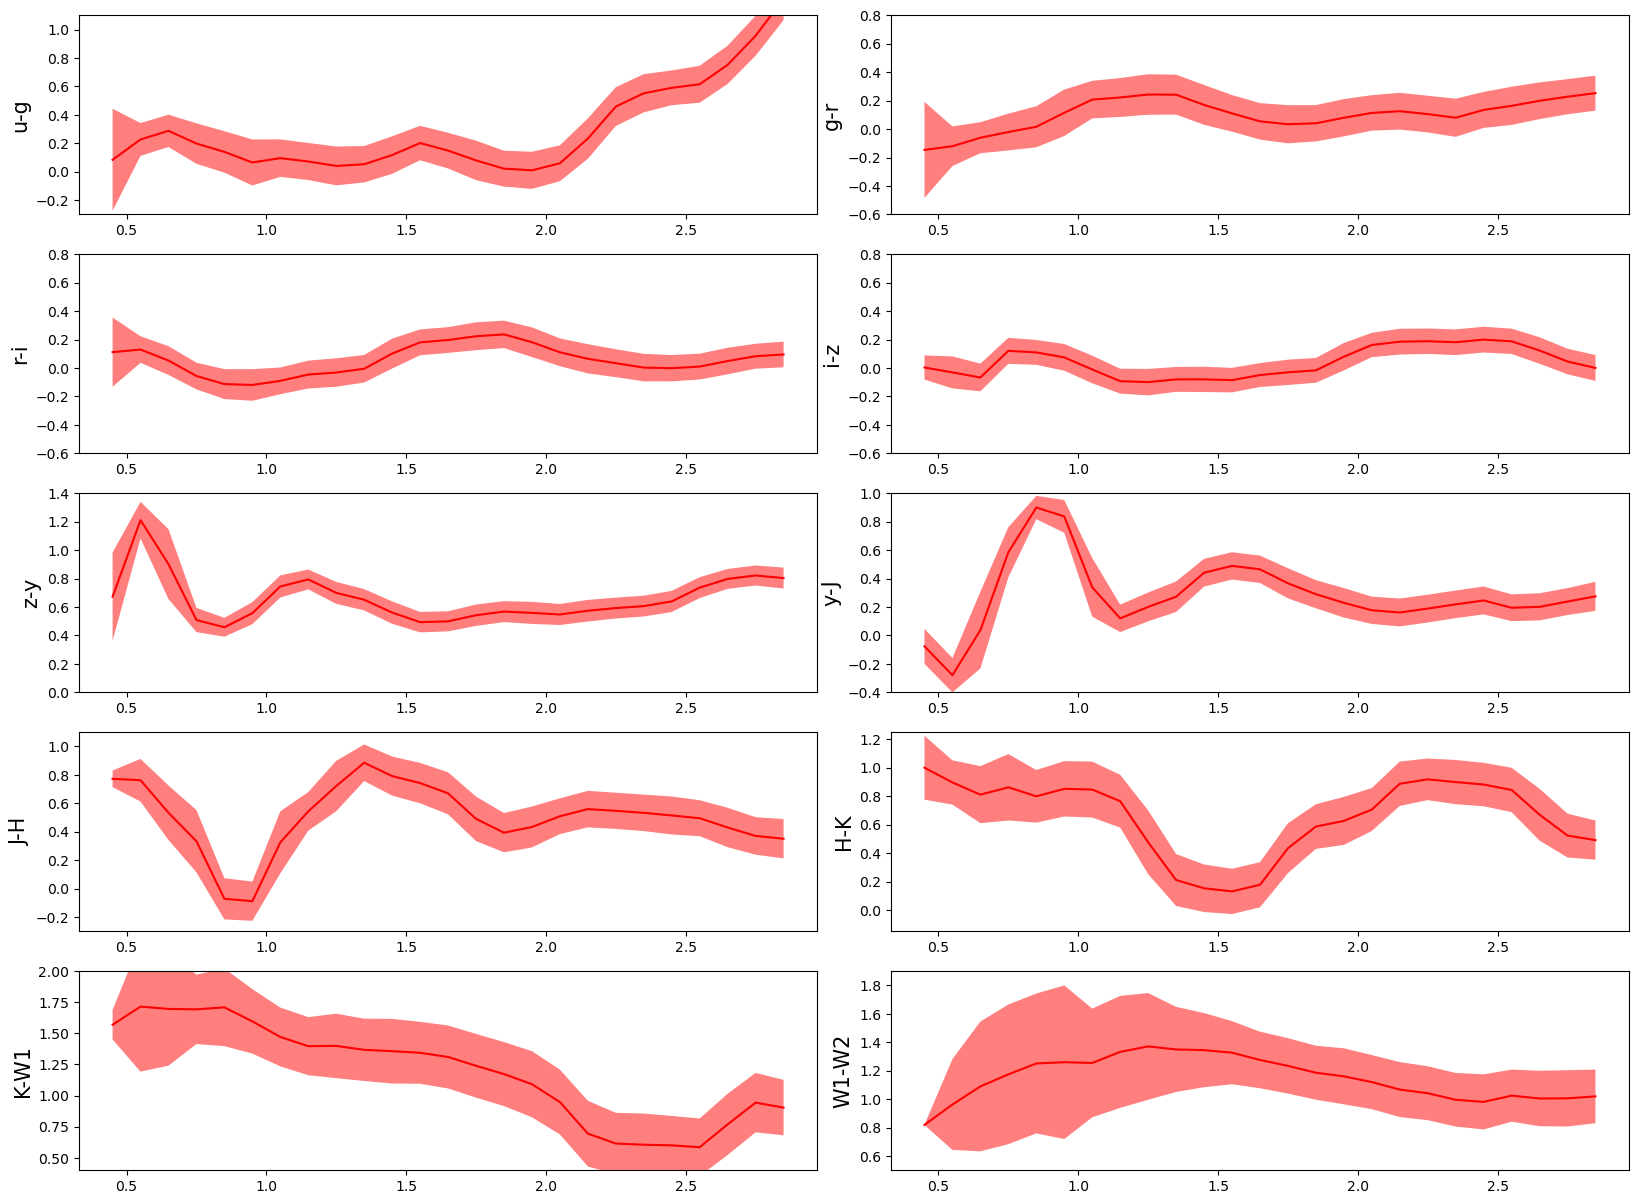

In [59]:
fig, axs = get_color_figure()
plot_color_filled(axs, mean_z, mean_sim_colors[..., 0],  mean_sim_colors[..., 1])


In [60]:
10000/200

50.0

In [70]:
dist = np.random.lognormal(mean = np.log(2.5), sigma = 1, size = 100000)

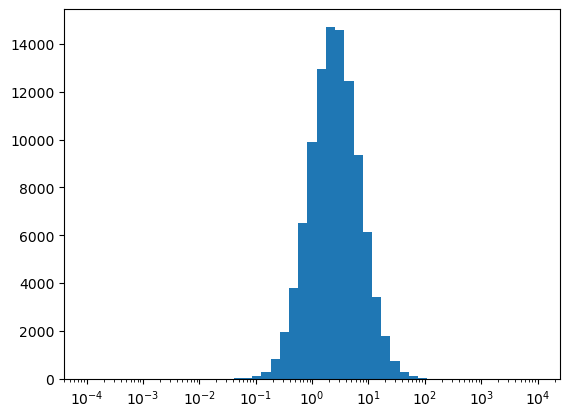

In [71]:
bins=np.logspace(-4, 4)
plt.hist(dist, bins = bins);
plt.xscale("log")

In [1]:
import numpy as np

In [10]:
mu_array = np.random.randn(5)
variance_array = np.random.randn(5)**2

In [11]:
def sample_from_normal(mu_array, variance_array, Nsamples):
    cov = np.diag(variance_array)
    return np.random.multivariate_normal(mu_array, cov, size = Nsamples)

In [12]:
sample_from_normal(mu_array, variance_array, 10)

array([[ 0.01394248,  1.72649396,  0.29597994,  1.55427595, -1.05091782],
       [ 0.4768837 ,  1.33620069, -0.06031714,  1.18020894, -0.93024221],
       [-0.06214191,  1.35972554,  0.12339793,  1.31639487, -1.75164785],
       [ 0.18641327,  1.76951459,  0.23228838,  1.22538445, -3.465833  ],
       [-0.13256327,  1.54841389,  0.18990782,  1.49421766, -2.43769359],
       [-0.12335185,  1.88951644,  0.20614406,  1.61087467, -2.30015486],
       [-0.18415553,  1.17526903,  0.18049698,  1.22950985, -2.19068567],
       [-0.13279429,  1.54909192,  0.23717644,  1.44995307, -0.90674783],
       [ 0.26023652,  1.68999835,  0.16778851,  1.49812355, -0.67440333],
       [ 0.29647107,  1.66227635, -0.02936722,  1.48972441, -2.82291025]])

In [ ]:
names = ["plslp1", "plslp2", "wavbrk", "TBB", "Norm_BB"]
fig, axs = plt.subplots(nrows =3, ncols =2, figsize = (15,10))
for idx in range(5):
    row = idx // 2
    col = idx % 2
    gauss = Normal(mu = median_mean[idx], sigma = median_sigma[idx])
    curve =  gauss.pdf(hist_centers[idx, :])
    curve = curve/np.sum(curve)
    axs[row,col].plot(hist_centers[idx, :], median_weights[idx,:], lw = 1, c= "k")
    axs[row,col].plot(hist_centers[idx, :],curve, lw = 2, c= "r")
    axs[row,col].set_xlabel(names[idx])

axs[2,1].set_axis_off()

In [32]:
def get_parameters_figure(nrows =3, ncols =2, figsize = (15,10), gridspec_kw = {"wspace": 0.1}):
    names = ["plslp1", "plslp2", "wavbrk", "T_BB", "Norm_BB"]
    fig, axs = plt.subplots(nrows =3, ncols =2, figsize = figsize, gridspec_kw=gridspec_kw)
    for idx in range(5):
        col = idx % 2
        row = idx // 2
        axs[row,col].set_xlabel(names[idx])
    axs[2,1].set_axis_off()
    return fig, axs


def plot_parameters_hist(axs, hist_centers, hist_weights, quantiles = [0.16, 0.84], 
                         sample_every = 100,
                         color = "k",
                         lw = 1,
                         edgecolor = "None",
                         alpha = 0.5, **kwargs):
    if len(hist_weights.shape) == 2:
        for idx in range(5):
            row = idx // 2
            col = idx % 2
            axs[row,col].plot(hist_centers[idx, :], hist_weights[idx,:], lw = lw, color = color, **kwargs)
    elif len(hist_weights.shape) == 3:
        median = np.median(hist_weights, axis = 0)
        if quantiles is not None:
            values = np.quantile(hist_weights, quantiles, axis = 0)
            for idx in range(5):
                row = idx // 2
                col = idx % 2
                axs[row,col].fill_between(hist_centers[idx, :], values[0, idx,:], values[1, idx,:],
                                        alpha = alpha, lw = lw, color = color, edgecolor = edgecolor, **kwargs)
                axs[row,col].plot(hist_centers[idx, :], median[idx,:], lw = lw, color = color, **kwargs)
        else:
            values = hist_weights[0::sample_every, ...]
            for idx in range(5):
                row = idx // 2
                col = idx % 2
                for val in values:
                    axs[row,col].plot(hist_centers[idx, :], val[idx,:], lw = lw/30, color = color, **kwargs)
                axs[row,col].plot(hist_centers[idx, :], median[idx,:], lw = lw, color = color, **kwargs)
                    




        
    



In [105]:
def generate_gaussians(x, mu, sigma, normalize = True):
    """ mu = nparams, Nrealizations
        x = nparams, nvalues
    """
    

    if x.ndim == 1:
        x = x[None, :, None]  
    elif x.ndim == 2:
        x = x[:, :, None] 
    
    if mu.ndim == 1:
        mu = mu[:, None, None]
    elif mu.ndim == 2:
        mu = mu[:, None, :]

    if sigma.ndim == 1:
        sigma = sigma[:, None, None]
    elif sigma.ndim == 2:
        sigma = sigma[:, None, :]
   
    y = norm.pdf(x, loc=mu, scale=sigma)
    if normalize:
        dx = np.diff(x, axis=1, prepend=x[:, :1, :])
        y = y / np.sum(y * dx, axis=1, keepdims=True)

    return y


In [122]:
def plot_parameters_normal(axs,  mean, var, xvalues = None, 
                         normalize = True,
                         quantiles = [0.16, 0.84], 
                         sample_every = 100,
                         color = "r",
                         lw = 1,
                         edgecolor = "None",
                         alpha = 0.5, **kwargs):
    if xvalues is None:
        xvalues = np.column_stack([np.linspace(-1.5,1.5, 300),
                                   np.linspace(-1.5,1.5, 300),
                                   np.linspace(1000,10000, 300),
                                   np.linspace(500,2500, 300),
                                   np.linspace(0,9, 300),]).T

    values = generate_gaussians(xvalues, mean, np.sqrt(var)).squeeze()
    if values.ndim == 2:   
        for idx in range(5):
            row = idx // 2
            col = idx % 2
            axs[row,col].plot(xvalues[idx, :], values[idx,:], lw = lw, color = color, **kwargs)
    elif values.ndim == 3:
        median = np.median(values, axis = 2)
        if quantiles is not None:
            values = np.quantile(values, quantiles, axis = 2)
            for idx in range(5):
                row = idx // 2
                col = idx % 2
                axs[row,col].fill_between(xvalues[idx, :], values[0, idx,:], values[1, idx,:],
                                        alpha = alpha, lw = lw, color = color, edgecolor = edgecolor, **kwargs)
                axs[row,col].plot(xvalues[idx, :], median[idx,:], lw = lw, color = color, **kwargs)
        else:
            for idx in range(5):
                row = idx // 2
                col = idx % 2
                for r in range(0, values.shape[2], sample_every):
                    axs[row, col].plot(xvalues[idx, :], values[idx, :, r], lw=lw/30, color=color, **kwargs)
                axs[row,col].plot(xvalues[idx, :], median[idx,:], lw = lw, color = color, **kwargs)
                    




In [123]:

mu = np.array([-0.1, 0.1, 5000, 1500, 4])[:,None] + np.random.randn(10000)[None, :]
sigma = np.array([1, 1, 1000, 500, 2])[:,None] * np.ones(10000)[None, :]

xvalues = np.column_stack([np.linspace(-1.5,1.5, 300),
                           np.linspace(-1.5,1.5, 300),
                           np.linspace(1000,10000, 300),
                           np.linspace(500,2500, 300),
                           np.linspace(0,9, 300)]).T


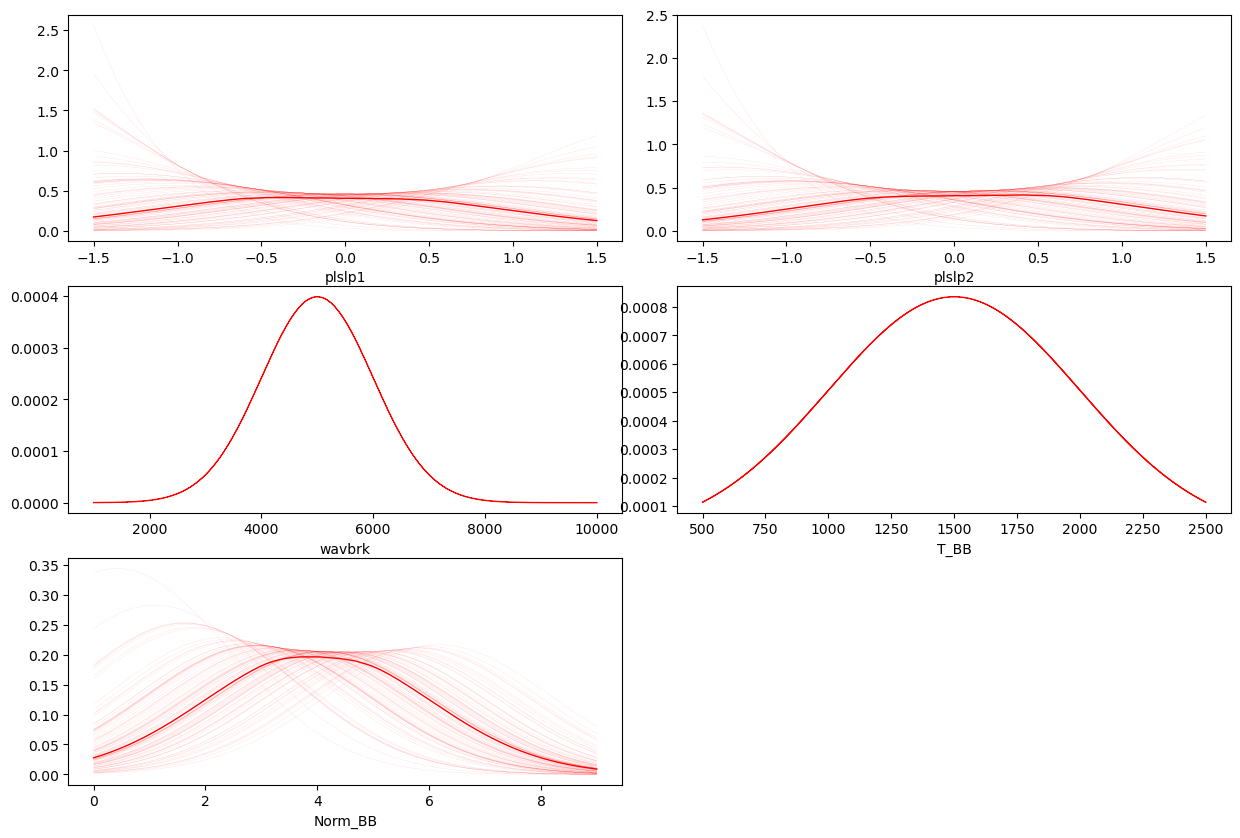

In [124]:
fig, ax = get_parameters_figure()
plot_parameters_normal(ax, mu, sigma**2, normalize=True, quantiles = None)

In [113]:
mu

array([[-1.14404266e-01, -7.28591212e-01, -7.29901319e-02, ...,
         5.09421191e-01,  1.60578721e-01, -1.39468879e+00],
       [ 8.55957336e-02, -5.28591212e-01,  1.27009868e-01, ...,
         7.09421191e-01,  3.60578721e-01, -1.19468879e+00],
       [ 4.99998560e+03,  4.99937141e+03,  5.00002701e+03, ...,
         5.00060942e+03,  5.00026058e+03,  4.99870531e+03],
       [ 1.49998560e+03,  1.49937141e+03,  1.50002701e+03, ...,
         1.50060942e+03,  1.50026058e+03,  1.49870531e+03],
       [ 3.98559573e+00,  3.37140879e+00,  4.02700987e+00, ...,
         4.60942119e+00,  4.26057872e+00,  2.70531121e+00]])

In [114]:
mu[0]

array([-0.11440427, -0.72859121, -0.07299013, ...,  0.50942119,
        0.16057872, -1.39468879])